In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All libraries imported. scikit-learn version:", sklearn.__version__)

All libraries imported. scikit-learn version: 1.9.1


In [2]:
df = pd.read_csv("Crop_recommendation.csv")

print(df.head())
print(df.shape)
df.info()
print(df.isnull().sum())
print(df["label"].value_counts())
print(df.describe())

    N   P   K  temperature   humidity        ph    rainfall label
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice
3  74  35  40    26.491096  80.158363  6.980401  242.864034  rice
4  78  42  42    20.130175  81.604873  7.628473  262.717340  rice
(2200, 8)
<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 137.6 KB
N              0
P 

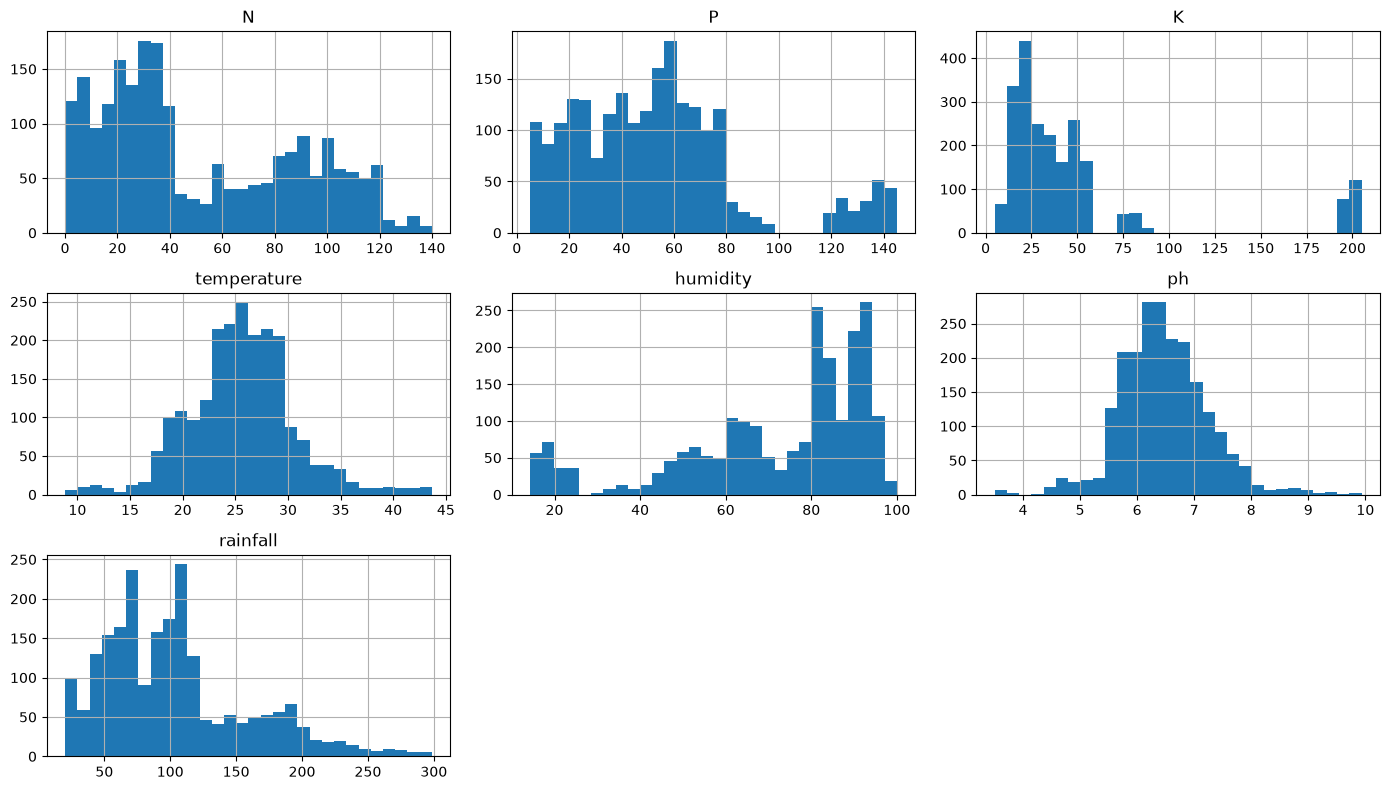

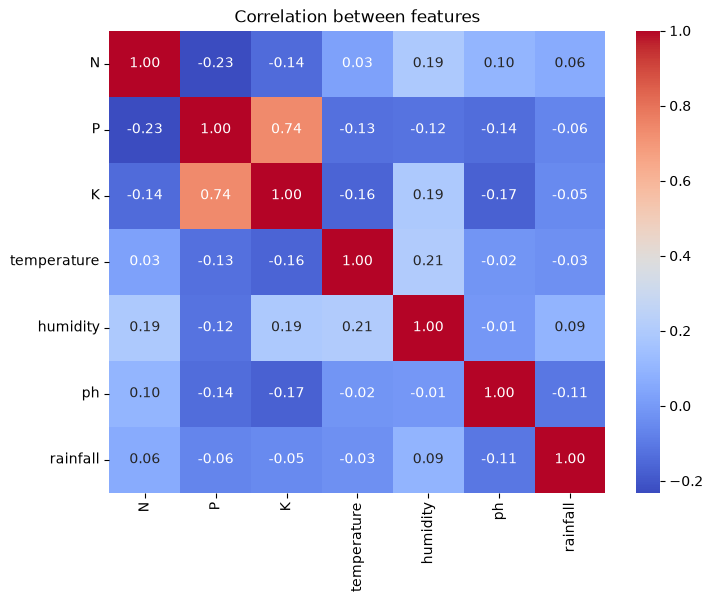

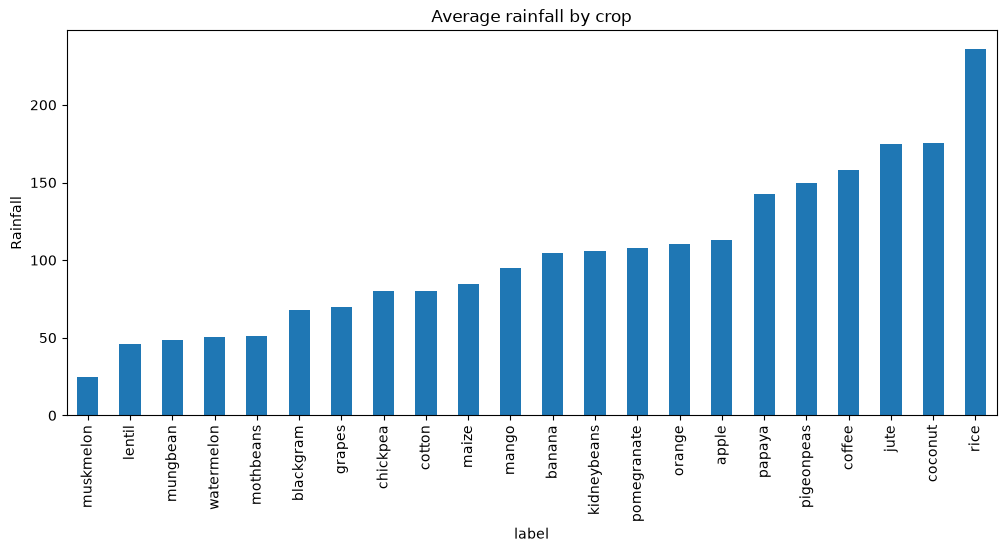

In [3]:
# 1. Distribution of each feature
features = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
df[features].hist(bins=30, figsize=(14, 8))
plt.tight_layout()
plt.show()

# 2. Correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df[features].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation between features")
plt.show()

# 3. Average rainfall per crop
plt.figure(figsize=(12, 5))
df.groupby("label")["rainfall"].mean().sort_values().plot(kind="bar")
plt.title("Average rainfall by crop")
plt.ylabel("Rainfall")
plt.show()

In [4]:
from sklearn.model_selection import train_test_split

features = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
X = df[features]      # inputs (features)
y = df["label"]       # what we want to predict (the crop)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 1760
Testing rows: 440


In [5]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)          # learning happens here

y_pred = dt_model.predict(X_test)       # predictions on unseen data

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9795454545454545
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.80      0.89        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      0.95      0.95        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       0.86      0.90      0.88        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.86      0.95      0.90        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        2

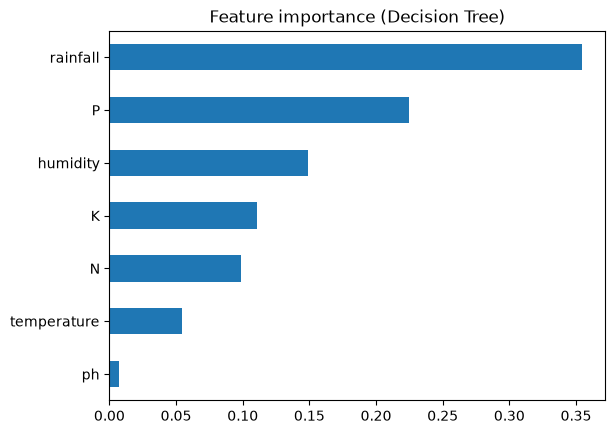

In [6]:
importance = pd.Series(dt_model.feature_importances_, index=features).sort_values()
importance.plot(kind="barh", title="Feature importance (Decision Tree)")
plt.show()

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import cross_val_score

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="macro"),
        "Recall": recall_score(y_test, pred, average="macro"),
        "F1": f1_score(y_test, pred, average="macro"),
        "CV Accuracy (5-fold)": cross_val_score(model, X, y, cv=5).mean(),
    })

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False).round(4)
print(results_df)

                 Model  Accuracy  Precision  Recall      F1  \
2        Random Forest    0.9955     0.9957  0.9955  0.9955   
1        Decision Tree    0.9795     0.9806  0.9795  0.9794   
0  Logistic Regression    0.9727     0.9740  0.9727  0.9725   

   CV Accuracy (5-fold)  
2                0.9945  
1                0.9868  
0                0.9714  


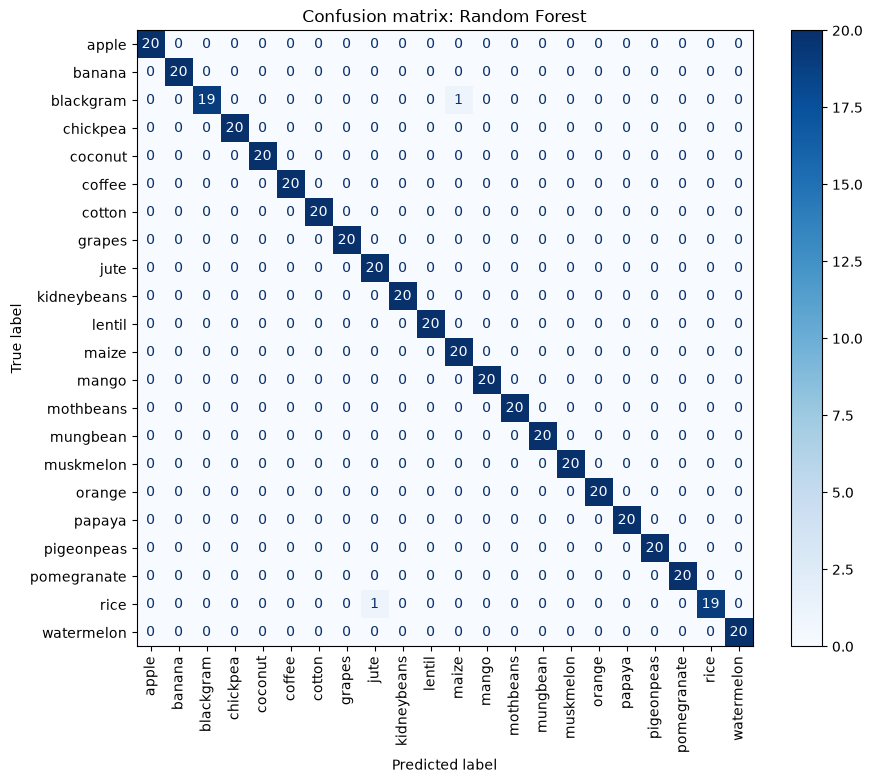

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay

best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_estimator(
    best_model, X_test, y_test, ax=ax, xticks_rotation=90, cmap="Blues"
)
plt.title(f"Confusion matrix: {best_name}")
plt.show()

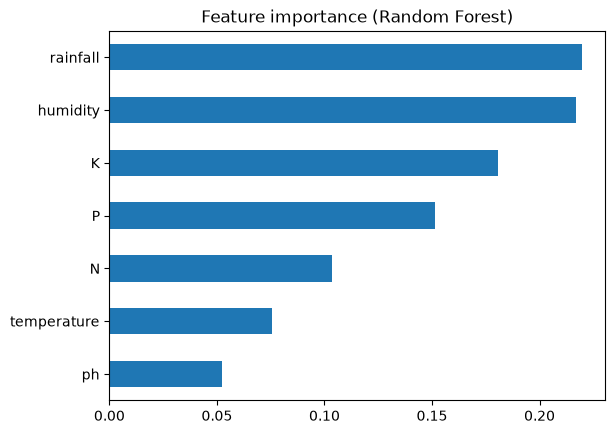

In [9]:
rf = models["Random Forest"]
rf_importance = pd.Series(rf.feature_importances_, index=features).sort_values()
rf_importance.plot(kind="barh", title="Feature importance (Random Forest)")
plt.show()

In [10]:
sample = pd.DataFrame([{
    "N": 90, "P": 42, "K": 43,
    "temperature": 21, "humidity": 82, "ph": 6.5, "rainfall": 203
}])

print("Recommended crop:", best_model.predict(sample)[0])

Recommended crop: rice


In [11]:
results_df.to_csv("model_comparison.csv", index=False)